# GlycoLens: Diabetes Risk Prediction
**End-to-end ML pipeline:** EDA → cleaning → feature engineering → encoding → baselines → comparison → tuning (Optuna) → threshold selection → explainability (SHAP) → deployment

Dataset: `diabetes_dataset.csv` (768 patients, 8 clinical features, target `Outcome`: 1 = diabetic).
Place the CSV in the same folder as this notebook.

## 1. Setup

In [1]:
# pip install pandas numpy matplotlib seaborn scikit-learn xgboost shap optuna joblib
import warnings, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import optuna
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, cross_val_score
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 2. Load and inspect data

In [2]:
df = pd.read_csv("diabetes_dataset.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148,72,35,0,33.6,0.627,50,1
1,1.0,85,66,29,0,26.6,0.351,31,0
2,8.0,183,64,0,0,23.3,0.672,32,1
3,1.0,89,66,23,94,28.1,0.167,21,0
4,NaN,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
display(df.describe().T)
print("Duplicates:", df.duplicated().sum())
print("Missing values:\n", df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               760 non-null    float64
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(3), int64(6)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,760.0,3.885526,3.363965,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Duplicates: 0
Missing values:
 Pregnancies                 8
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


**Data-quality findings.**
- `Pregnancies` has a few true missing values.
- In `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI`, a value of **0 is physiologically impossible**, so zeros are really hidden missing values. We check how many.

In [4]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
pd.DataFrame({"zeros": (df[zero_cols] == 0).sum(),
              "percent": ((df[zero_cols] == 0).mean() * 100).round(1)})

,zeros,percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


## 3. Exploratory data analysis

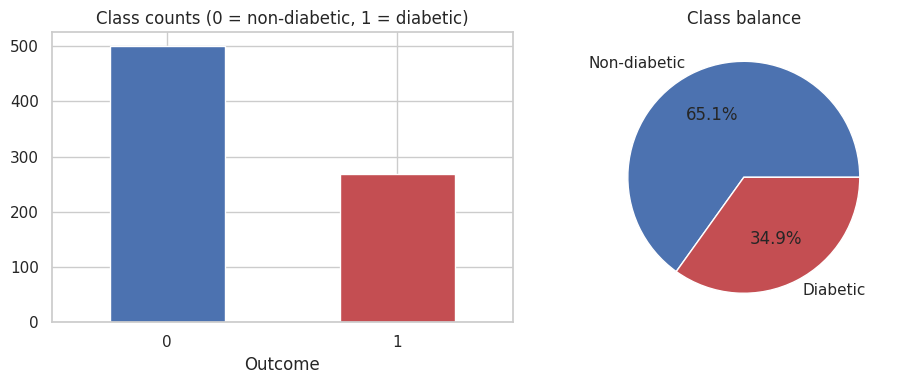

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df["Outcome"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Class counts (0 = non-diabetic, 1 = diabetic)")
ax[0].set_xticklabels(["0", "1"], rotation=0)
ax[1].pie(df["Outcome"].value_counts(), labels=["Non-diabetic", "Diabetic"], autopct="%1.1f%%",
          colors=["#4C72B0", "#C44E52"])
ax[1].set_title("Class balance")
plt.tight_layout(); plt.show()

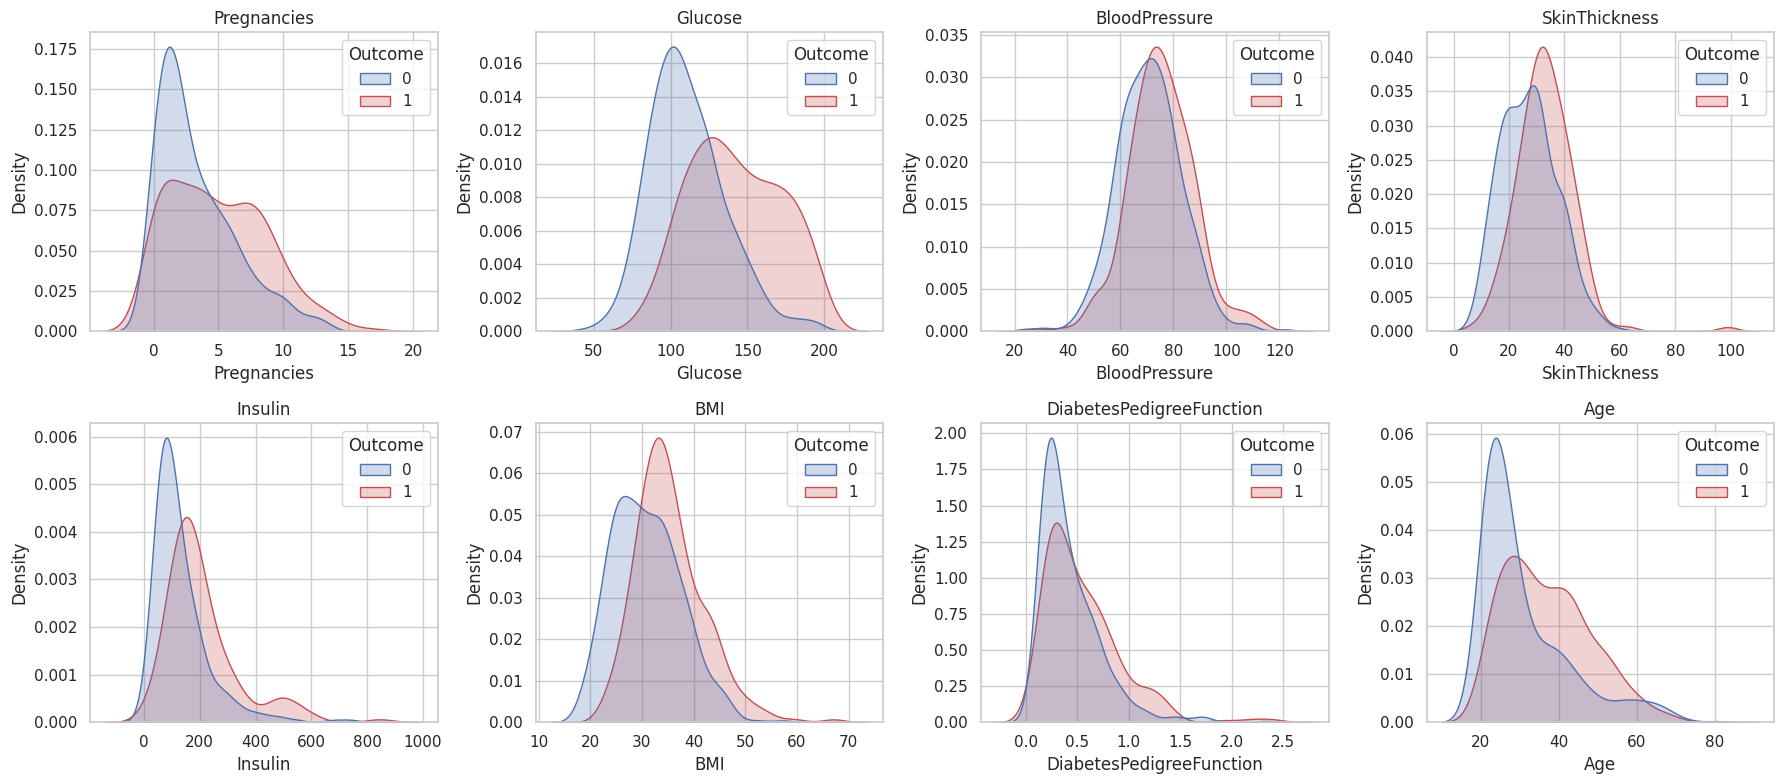

In [6]:
# Distributions by outcome (zeros treated as missing for plotting)
plot_df = df.copy()
plot_df[zero_cols] = plot_df[zero_cols].replace(0, np.nan)
feats = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for a, c in zip(axes.ravel(), feats):
    sns.kdeplot(data=plot_df, x=c, hue="Outcome", fill=True, common_norm=False, ax=a, palette=["#4C72B0", "#C44E52"])
    a.set_title(c)
plt.tight_layout(); plt.show()

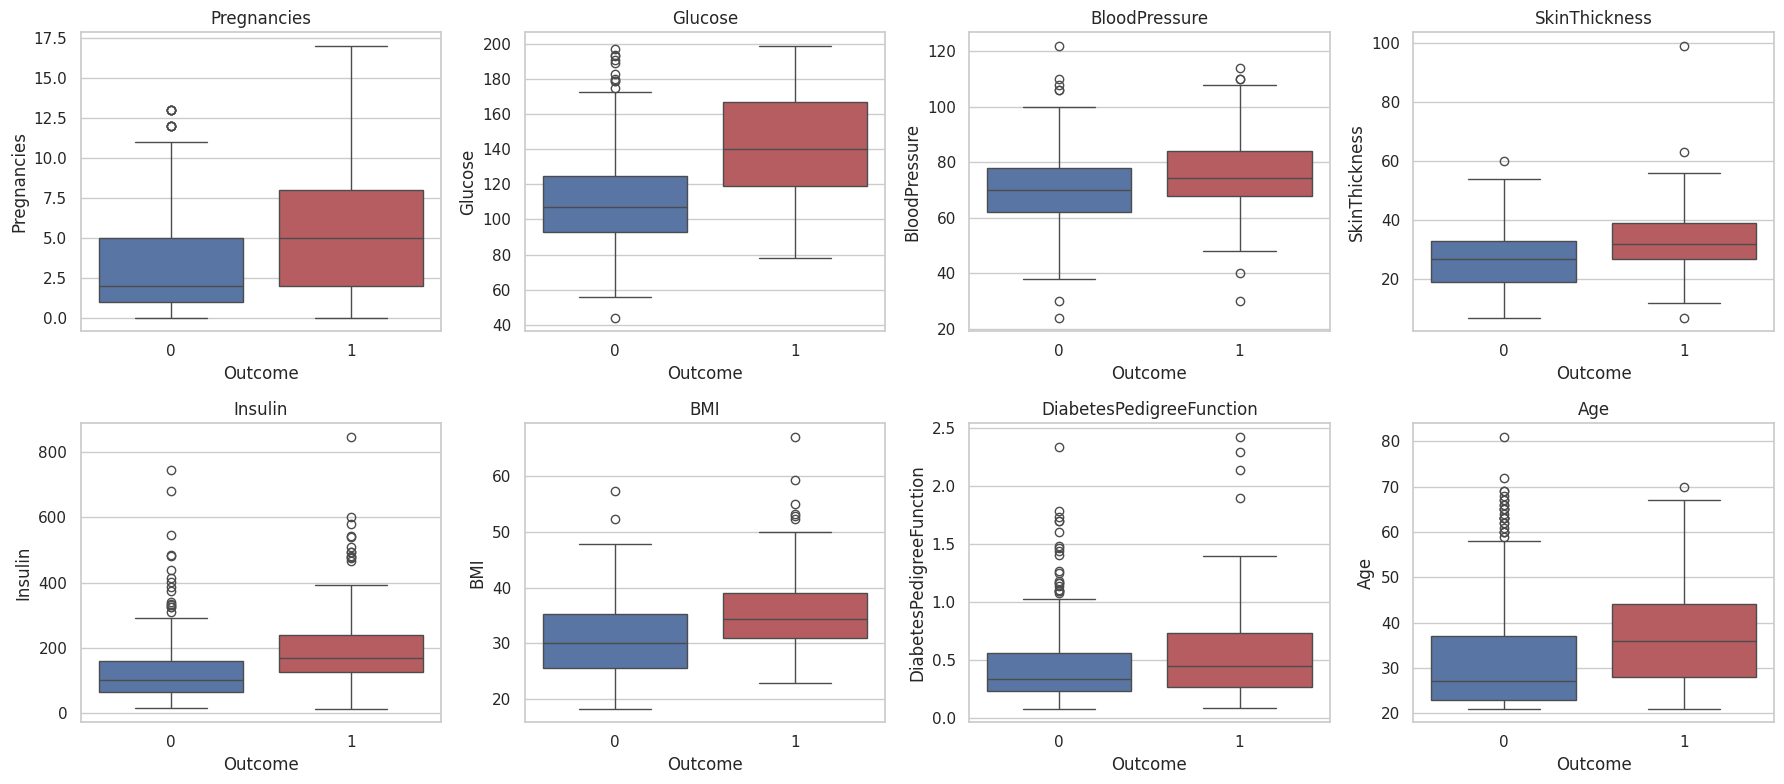

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for a, c in zip(axes.ravel(), feats):
    sns.boxplot(data=plot_df, x="Outcome", y=c, ax=a, palette=["#4C72B0", "#C44E52"])
    a.set_title(c)
plt.tight_layout(); plt.show()

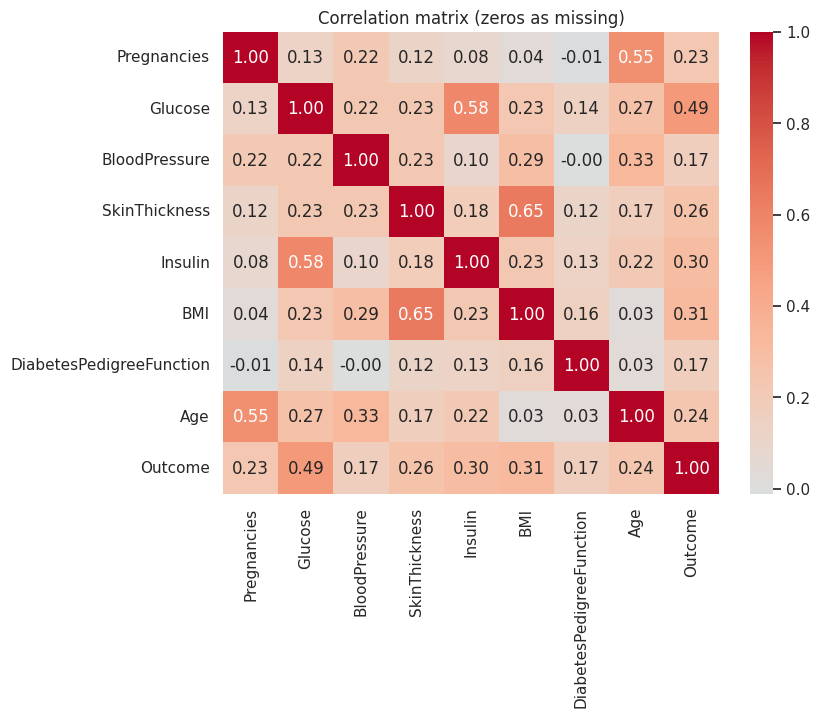

Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.232109
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64


In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(plot_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (zeros as missing)")
plt.show()
print(plot_df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False))

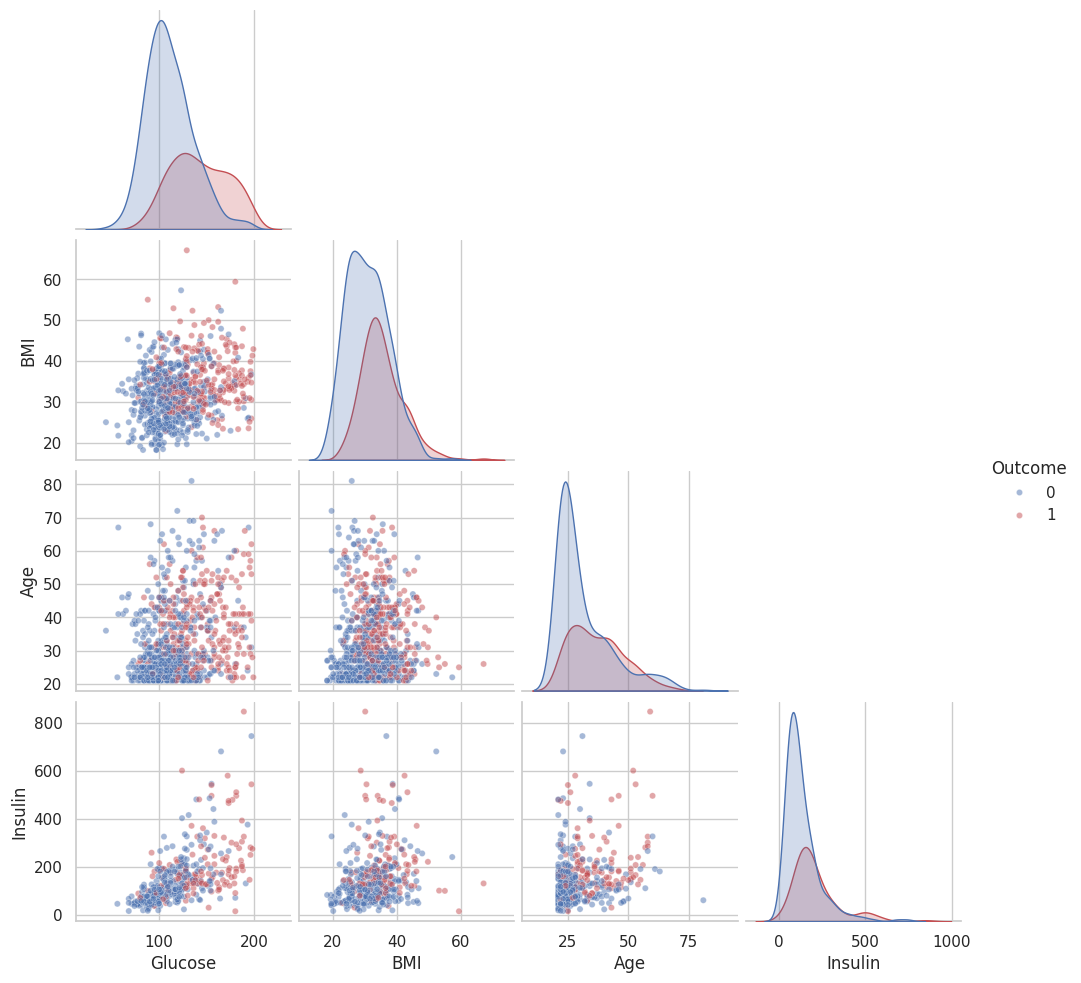

In [9]:
sns.pairplot(plot_df[["Glucose", "BMI", "Age", "Insulin", "Outcome"]], hue="Outcome",
             palette=["#4C72B0", "#C44E52"], corner=True, plot_kws={"alpha": 0.5, "s": 20})
plt.show()

**EDA takeaways.** The classes are moderately imbalanced (about 35% diabetic). `Glucose` is by far the strongest signal, followed by `BMI`, `Age` and `Pregnancies`. `Insulin` and `SkinThickness` have heavy missingness and long right tails, so they need careful imputation and outlier handling.

## 4. Train/test split
We split **first**, then fit every preprocessing step only on the training data, so no information leaks from the test set.

In [10]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print("Train positive rate:", y_train.mean().round(3), "| Test positive rate:", y_test.mean().round(3))

(614, 8) (154, 8)
Train positive rate: 0.349 | Test positive rate: 0.351


## 5. Preprocessing pipeline
Steps, all inside one scikit-learn pipeline (so cross-validation stays leak-free):
1. **Zeros → NaN** in the 5 columns where zero is impossible
2. **Median imputation** (robust to skew), learned on training data only
3. **Winsorising** outliers using IQR fences learned on training data
4. **Feature engineering:** `BMI_Category`, `Age_Group`, `Glucose_BMI` interaction, `Glucose_Age` interaction
5. **Encoding:** one-hot for the two new categorical features
6. **Scaling:** standardisation for the numeric features

In [11]:
%%writefile glycolens_utils.py
import numpy as np, pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

ZERO_COLS = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

def zeros_to_nan(X):
    X = X.copy()
    X[ZERO_COLS] = X[ZERO_COLS].replace(0, np.nan)
    return X

class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip columns to [Q1 - k*IQR, Q3 + k*IQR] learned on the training data."""
    def __init__(self, cols=None, k=1.5):
        self.cols = cols; self.k = k
    def fit(self, X, y=None):
        self.bounds_ = {}
        for c in self.cols:
            q1, q3 = X[c].quantile([0.25, 0.75]); iqr = q3 - q1
            self.bounds_[c] = (q1 - self.k * iqr, q3 + self.k * iqr)
        return self
    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in self.bounds_.items():
            X[c] = X[c].clip(lo, hi)
        return X

def add_features(X):
    X = X.copy()
    X["BMI_Category"] = pd.cut(X["BMI"], [0, 18.5, 25, 30, 100],
                               labels=["Underweight", "Normal", "Overweight", "Obese"]).astype(str)
    X["Age_Group"] = pd.cut(X["Age"], [0, 30, 45, 120], labels=["Young", "Middle", "Senior"]).astype(str)
    X["Glucose_BMI"] = X["Glucose"] * X["BMI"] / 100
    X["Glucose_Age"] = X["Glucose"] * X["Age"] / 100
    return X

Writing glycolens_utils.py


The custom steps live in a small module file (`glycolens_utils.py`, written by the cell above) so the saved model can be loaded later from any script, such as the Streamlit app.

In [12]:
from glycolens_utils import zeros_to_nan, Winsorizer, add_features
base_num = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI",
            "DiabetesPedigreeFunction", "Age"]
num_cols = base_num + ["Glucose_BMI", "Glucose_Age"]
cat_cols = ["BMI_Category", "Age_Group"]
wins_cols = [c for c in base_num if c != "Glucose"]

def make_preprocessor():
    encode_scale = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
         ("num", StandardScaler(), num_cols)],
        verbose_feature_names_out=False).set_output(transform="pandas")
    return make_pipeline(
        FunctionTransformer(zeros_to_nan),
        SimpleImputer(strategy="median").set_output(transform="pandas"),
        Winsorizer(cols=wins_cols),
        FunctionTransformer(add_features),
        encode_scale)

prep = make_preprocessor().fit(X_train)
X_train_t = prep.transform(X_train)
print("Features after preprocessing:", X_train_t.shape[1])
X_train_t.head()

Features after preprocessing: 17


,BMI_Category_Normal,BMI_Category_Obese,BMI_Category_Overweight,BMI_Category_Underweight,Age_Group_Middle,Age_Group_Senior,Age_Group_Young,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Glucose_BMI,Glucose_Age
353,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.871964,-1.056427,-0.858066,-1.910489,-1.473258,-0.785079,0.393103,-0.798419,-1.077154,-0.959738
711,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.353176,0.144399,0.500239,-0.243007,-1.473258,-0.421652,-0.093401,0.572372,-0.179696,0.424972
373,0.0,1.0,0.0,0.0,0.0,0.0,1.0,-0.565679,-0.556083,-1.197642,1.491175,-1.473258,0.380916,-0.831784,-0.712745,-0.225283,-0.736165
46,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.871964,0.811525,-1.367431,0.023790,0.006507,-0.406509,0.337897,-0.370047,0.245085,0.037445
682,0.0,1.0,0.0,0.0,0.0,0.0,1.0,-1.178249,-0.889646,-0.688278,1.357776,-1.473258,1.849765,-0.345280,-0.969768,0.175618,-0.993394


## 6. Baseline models
Eight different model families, each wrapped with the preprocessing pipeline and evaluated with **stratified 5-fold cross-validation on the training set only**. Class weights are used where available to handle the imbalance.

In [13]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF)":           SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),
    "Naive Bayes":         GaussianNB(),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost":             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, scale_pos_weight=pos_weight,
                                         eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, est in models.items():
    pipe = make_pipeline(make_preprocessor(), est)
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{m: s[f"test_{m}"].mean() for m in scoring},
                 "roc_auc_std": s["test_roc_auc"].std()})
baseline = pd.DataFrame(rows).set_index("Model").sort_values("roc_auc", ascending=False).round(3)
baseline

,accuracy,precision,recall,f1,roc_auc,roc_auc_std
Model,,,,,,
Logistic Regression,0.769,0.643,0.766,0.698,0.847,0.014
SVM (RBF),0.769,0.646,0.767,0.698,0.839,0.024
KNN,0.762,0.705,0.575,0.627,0.827,0.028
Naive Bayes,0.557,0.439,0.967,0.604,0.825,0.026
Random Forest,0.759,0.692,0.565,0.620,0.823,0.029
Gradient Boosting,0.741,0.645,0.598,0.617,0.813,0.027
XGBoost,0.741,0.617,0.691,0.650,0.805,0.034
Decision Tree,0.726,0.591,0.753,0.654,0.785,0.019


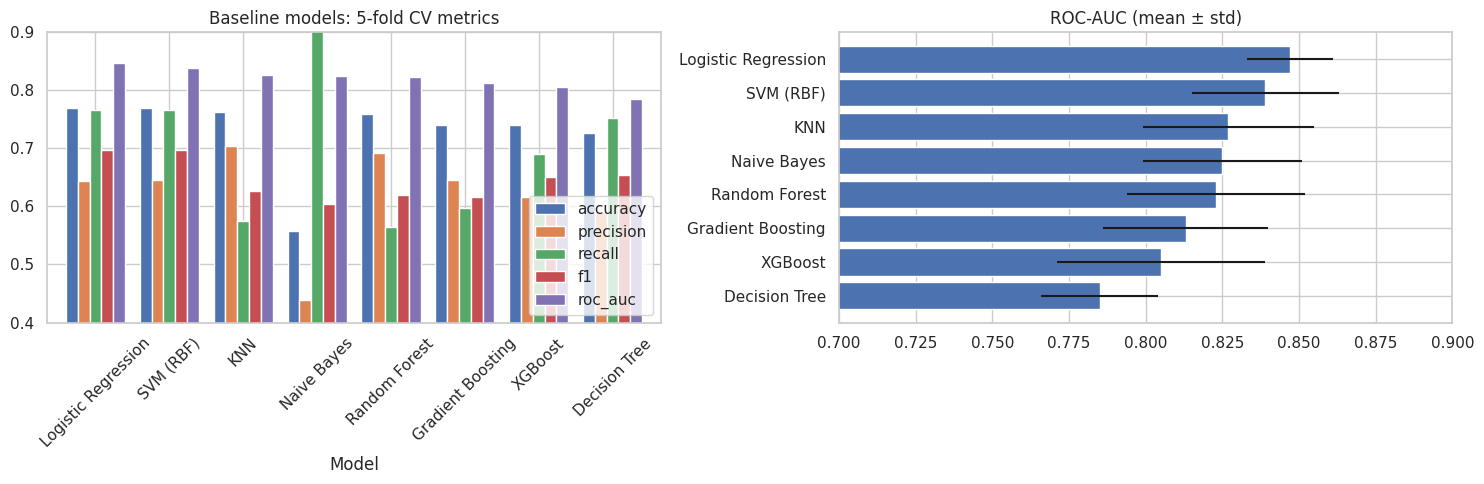

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
baseline[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot.bar(ax=ax[0], width=0.8)
ax[0].set_title("Baseline models: 5-fold CV metrics"); ax[0].set_ylim(0.4, 0.9); ax[0].legend(loc="lower right")
ax[0].tick_params(axis="x", rotation=45)
ax[1].barh(baseline.index[::-1], baseline["roc_auc"][::-1], xerr=baseline["roc_auc_std"][::-1], color="#4C72B0")
ax[1].set_title("ROC-AUC (mean ± std)"); ax[1].set_xlim(0.7, 0.9)
plt.tight_layout(); plt.show()

**Metric note.** For a screening problem, *recall* (not missing diabetic patients) matters a lot, but accuracy alone can mislead on imbalanced data. We rank models by **ROC-AUC** (threshold-independent) and adjust the decision threshold separately in section 8.

## 7. Hyperparameter tuning with Optuna
We tune three promising and different families (Logistic Regression, Random Forest, XGBoost) by maximising 5-fold CV ROC-AUC on the training set.

In [15]:
def tune(name, objective, n_trials=40):
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    print(f"{name:20s} best CV ROC-AUC = {study.best_value:.4f}")
    return study

def cv_auc(est):
    return cross_val_score(make_pipeline(make_preprocessor(), est), X_train, y_train,
                           cv=cv, scoring="roc_auc", n_jobs=-1).mean()

def lr_params(t):
    return dict(C=t.suggest_float("C", 1e-3, 100, log=True),
                penalty=t.suggest_categorical("penalty", ["l1", "l2"]))
def lr_obj(t):
    p = lr_params(t)
    return cv_auc(LogisticRegression(solver="liblinear", max_iter=2000, class_weight="balanced",
                                     random_state=RANDOM_STATE, **p))

def rf_params(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 100, 500),
                max_depth=t.suggest_int("max_depth", 3, 12),
                min_samples_split=t.suggest_int("min_samples_split", 2, 20),
                min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 10),
                max_features=t.suggest_categorical("max_features", ["sqrt", "log2", 0.5]))
def rf_obj(t):
    return cv_auc(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, **rf_params(t)))

def xgb_params(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 100, 600),
                learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                max_depth=t.suggest_int("max_depth", 2, 6),
                min_child_weight=t.suggest_int("min_child_weight", 1, 10),
                subsample=t.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.6, 1.0),
                reg_lambda=t.suggest_float("reg_lambda", 1e-2, 10, log=True))
def xgb_obj(t):
    return cv_auc(XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss",
                                random_state=RANDOM_STATE, n_jobs=-1, **xgb_params(t)))

studies = {"Logistic Regression": tune("Logistic Regression", lr_obj),
           "Random Forest":       tune("Random Forest", rf_obj),
           "XGBoost":             tune("XGBoost", xgb_obj)}

Logistic Regression  best CV ROC-AUC = 0.8517


Random Forest        best CV ROC-AUC = 0.8442


XGBoost              best CV ROC-AUC = 0.8448


In [16]:
tuned_estimators = {
    "Logistic Regression (tuned)": LogisticRegression(solver="liblinear", max_iter=2000, class_weight="balanced",
                                                      random_state=RANDOM_STATE, **studies["Logistic Regression"].best_params),
    "Random Forest (tuned)": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
                                                    **studies["Random Forest"].best_params),
    "XGBoost (tuned)": XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss",
                                     random_state=RANDOM_STATE, n_jobs=-1, **studies["XGBoost"].best_params),
}
rows = []
for name, est in tuned_estimators.items():
    s = cross_validate(make_pipeline(make_preprocessor(), est), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{m: s[f"test_{m}"].mean() for m in scoring}, "roc_auc_std": s["test_roc_auc"].std()})
tuned = pd.DataFrame(rows).set_index("Model").round(3)
comparison = pd.concat([baseline, tuned]).sort_values("roc_auc", ascending=False)
comparison

,accuracy,precision,recall,f1,roc_auc,roc_auc_std
Model,,,,,,
Logistic Regression (tuned),0.774,0.663,0.720,0.689,0.852,0.015
Logistic Regression,0.769,0.643,0.766,0.698,0.847,0.014
XGBoost (tuned),0.772,0.642,0.794,0.709,0.845,0.019
Random Forest (tuned),0.770,0.642,0.776,0.702,0.844,0.023
SVM (RBF),0.769,0.646,0.767,0.698,0.839,0.024
KNN,0.762,0.705,0.575,0.627,0.827,0.028
Naive Bayes,0.557,0.439,0.967,0.604,0.825,0.026
Random Forest,0.759,0.692,0.565,0.620,0.823,0.029
Gradient Boosting,0.741,0.645,0.598,0.617,0.813,0.027


Logistic Regression {'C': 0.09292716082125703, 'penalty': 'l1'}
Random Forest {'n_estimators': 228, 'max_depth': 3, 'min_samples_split': 12, 'min_samples_leaf': 8, 'max_features': 'log2'}
XGBoost {'n_estimators': 120, 'learning_rate': 0.018879330014066133, 'max_depth': 2, 'min_child_weight': 5, 'subsample': 0.8048299779352738, 'colsample_bytree': 0.8062586850499683, 'reg_lambda': 1.2048396868931854}


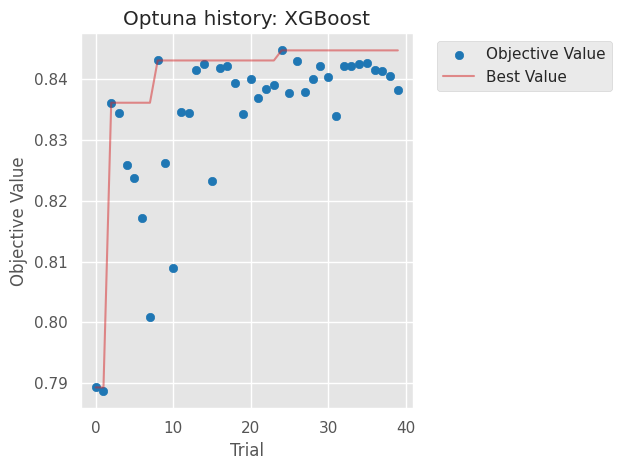

In [17]:
for n, s in studies.items():
    print(n, s.best_params)
optuna.visualization.matplotlib.plot_optimization_history(studies["XGBoost"])
plt.title("Optuna history: XGBoost"); plt.show()

## 8. Final model selection and threshold tuning
The final model is chosen by **cross-validated** ROC-AUC (never by test score). The decision threshold is then picked from **out-of-fold training predictions**, maximising F1, so the test set stays untouched until the final evaluation.

Selected model: Logistic Regression (tuned)


Chosen threshold: 0.480 (default 0.5)


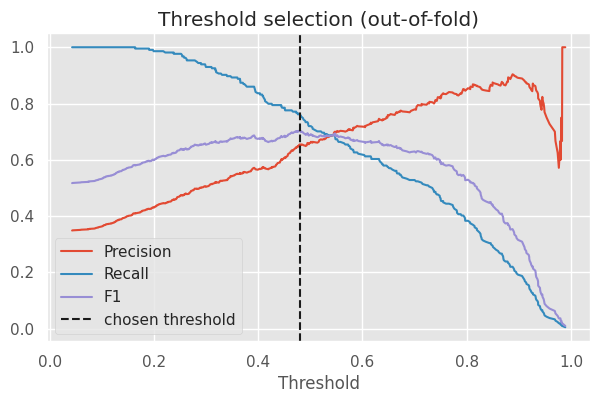

In [18]:
best_name = tuned["roc_auc"].idxmax()
print("Selected model:", best_name)
final_pipe = make_pipeline(make_preprocessor(), clone(tuned_estimators[best_name]))

oof_proba = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = float(thr[np.argmax(f1s)])
print(f"Chosen threshold: {best_thr:.3f} (default 0.5)")

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall"); plt.plot(thr, f1s, label="F1")
plt.axvline(best_thr, color="k", ls="--", label="chosen threshold")
plt.xlabel("Threshold"); plt.legend(); plt.title("Threshold selection (out-of-fold)"); plt.show()

## 9. Final evaluation on the held-out test set

In [19]:
final_pipe.fit(X_train, y_train)
proba = final_pipe.predict_proba(X_test)[:, 1]

def report(pred, label):
    return {"Setting": label, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba)}

pd.DataFrame([report((proba >= 0.5).astype(int), "Threshold 0.5"),
              report((proba >= best_thr).astype(int), f"Threshold {best_thr:.2f}")]).set_index("Setting").round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Setting,,,,,
Threshold 0.5,0.753,0.625,0.741,0.678,0.816
Threshold 0.48,0.747,0.612,0.759,0.678,0.816


              precision    recall  f1-score   support

Non-diabetic       0.85      0.74      0.79       100
    Diabetic       0.61      0.76      0.68        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.73       154
weighted avg       0.77      0.75      0.75       154


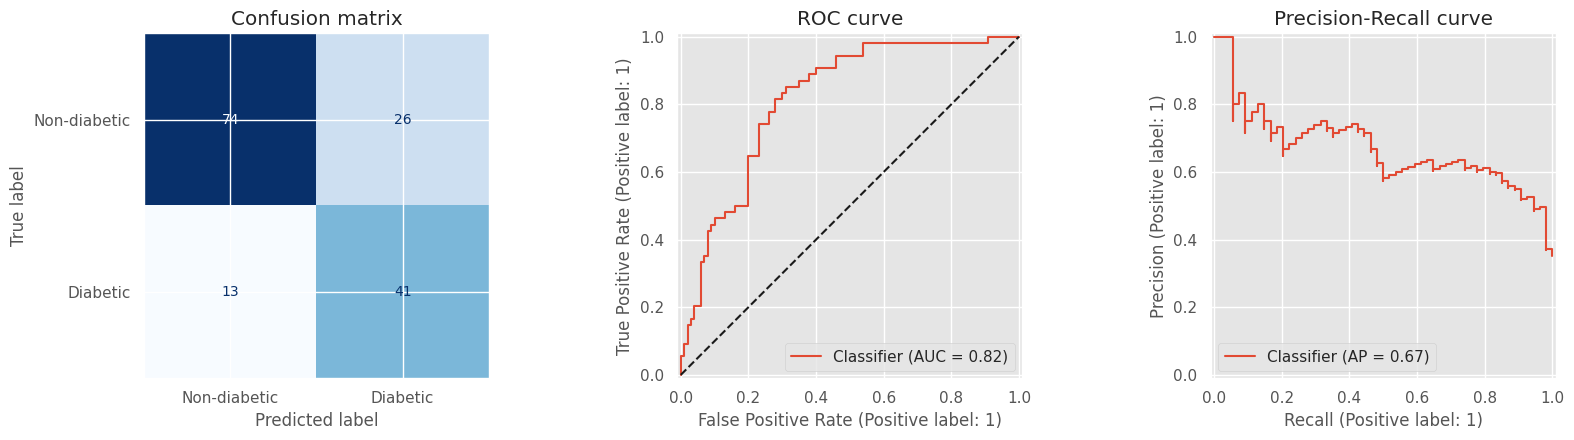

In [20]:
pred = (proba >= best_thr).astype(int)
print(classification_report(y_test, pred, target_names=["Non-diabetic", "Diabetic"]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Non-diabetic", "Diabetic"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1]); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[2]); ax[2].set_title("Precision-Recall curve")
plt.tight_layout(); plt.show()

With only 154 test patients, every metric has noticeable uncertainty (a single patient moves recall by about 2 points). Cross-validation results in section 7 are the more stable guide; the test set is the final sanity check.

## 10. Explainability
Two views: **permutation importance** (model-agnostic, on the raw test features) and **SHAP** (how each feature pushes an individual prediction).

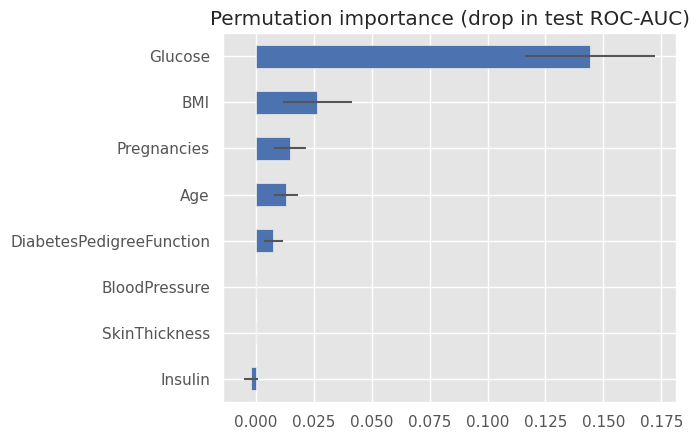

In [21]:
perm = permutation_importance(final_pipe, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(7, 4.5))
imp.plot.barh(xerr=pd.Series(perm.importances_std, index=X_test.columns)[imp.index], color="#4C72B0")
plt.title("Permutation importance (drop in test ROC-AUC)"); plt.tight_layout(); plt.show()

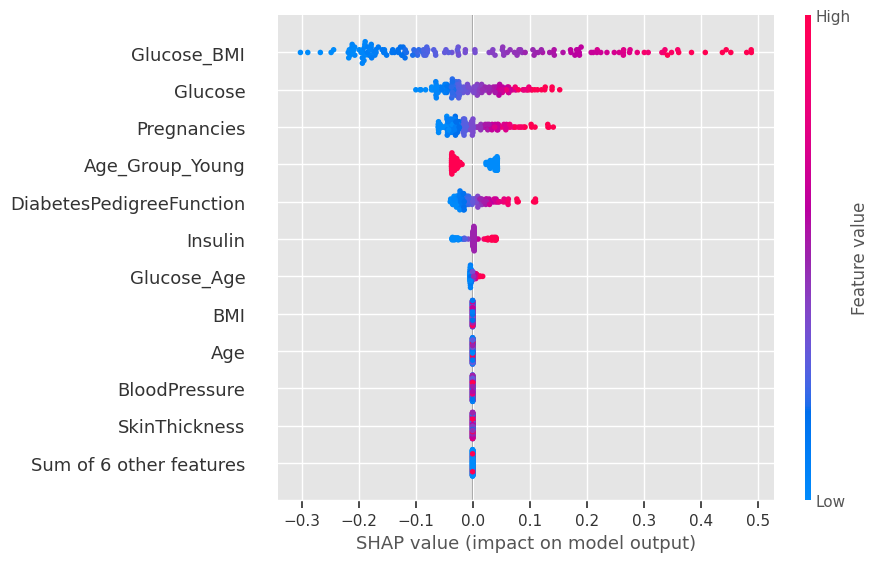

In [22]:
fitted_prep, fitted_est = final_pipe[0], final_pipe[-1]
Xt_train = fitted_prep.transform(X_train)
Xt_test = fitted_prep.transform(X_test)

predict_pos = lambda d: fitted_est.predict_proba(d)[:, 1]
explainer = shap.Explainer(predict_pos, shap.sample(Xt_train, 100, random_state=RANDOM_STATE))
shap_values = explainer(Xt_test)

shap.plots.beeswarm(shap_values, max_display=12)

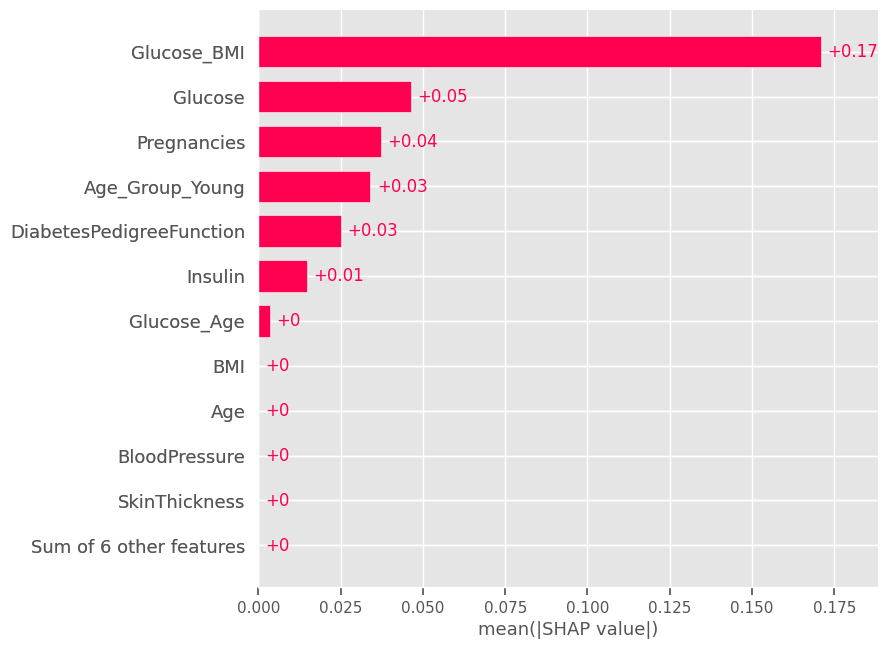

Highest-risk test patient | predicted risk: 0.976 | actual: 1


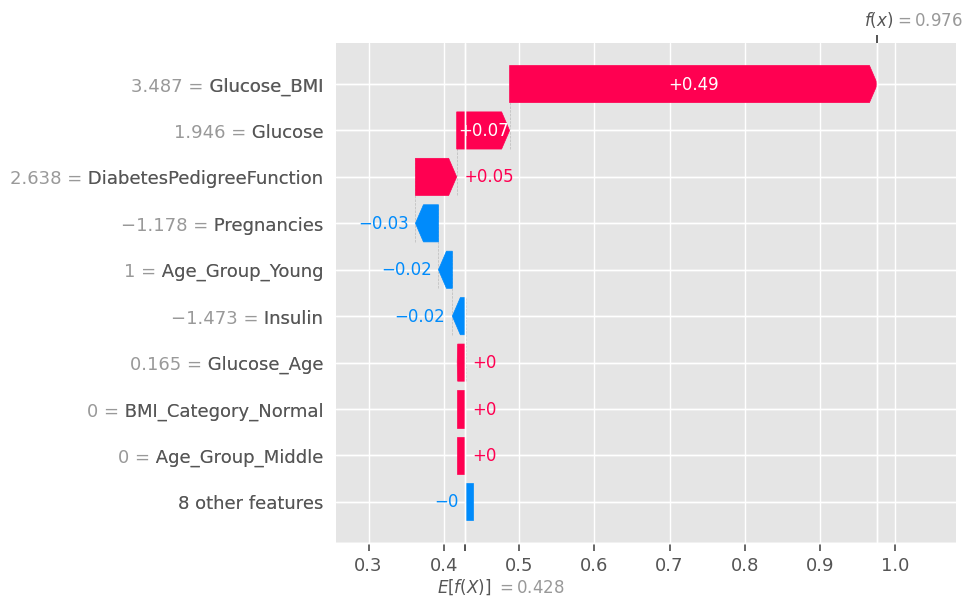

In [23]:
shap.plots.bar(shap_values, max_display=12)
# Local explanation for one test patient
i = int(np.argmax(proba))
print("Highest-risk test patient | predicted risk:", round(float(proba[i]), 3), "| actual:", int(y_test.iloc[i]))
shap.plots.waterfall(shap_values[i], max_display=10)

**Interpretation.** `Glucose` is by far the most important feature (together with the `Glucose_BMI` interaction built from it), followed by `BMI`, `Pregnancies` and `Age`. This agrees with clinical knowledge and with the EDA, which is a good sign that the model learned real signal rather than artefacts. `BloodPressure`, `SkinThickness` and `Insulin` add almost nothing here, partly because of their heavy hidden missingness.

## 11. Save the model and predict on new patients

In [24]:
joblib.dump(final_pipe, "glycolens_model.joblib")
json.dump({"threshold": best_thr, "model": best_name}, open("glycolens_config.json", "w"))

def predict_patient(record: dict):
    model = joblib.load("glycolens_model.joblib")
    thr = json.load(open("glycolens_config.json"))["threshold"]
    p = float(model.predict_proba(pd.DataFrame([record]))[:, 1][0])
    return {"risk_probability": round(p, 3), "prediction": "High risk" if p >= thr else "Low risk"}

predict_patient({"Pregnancies": 2, "Glucose": 150, "BloodPressure": 80, "SkinThickness": 30,
                 "Insulin": 0, "BMI": 34.0, "DiabetesPedigreeFunction": 0.6, "Age": 45})

{'risk_probability': 0.739, 'prediction': 'High risk'}

## 12. Deployment: Streamlit app
The next cell writes `app.py`. Run it from a terminal in this folder with `pip install streamlit` then `streamlit run app.py`.

In [25]:
%%writefile app.py
import json, joblib, pandas as pd, streamlit as st

st.set_page_config(page_title="GlycoLens", page_icon="🩸")
st.title("🩸 GlycoLens: Diabetes Risk Predictor")
st.caption("Educational ML project. Not a medical diagnosis.")

model = joblib.load("glycolens_model.joblib")
thr = json.load(open("glycolens_config.json"))["threshold"]

c1, c2 = st.columns(2)
preg = c1.number_input("Pregnancies", 0, 20, 1)
glu = c1.number_input("Glucose (mg/dL)", 40, 300, 120)
bp = c1.number_input("Blood pressure (mm Hg)", 30, 140, 70)
skin = c1.number_input("Skin thickness (mm)", 0, 100, 20)
ins = c2.number_input("Insulin (mu U/ml, 0 if unknown)", 0, 900, 80)
bmi = c2.number_input("BMI", 10.0, 70.0, 28.0)
dpf = c2.number_input("Diabetes pedigree function", 0.05, 2.5, 0.45)
age = c2.number_input("Age", 15, 100, 33)

if st.button("Predict"):
    row = pd.DataFrame([{"Pregnancies": preg, "Glucose": glu, "BloodPressure": bp, "SkinThickness": skin,
                         "Insulin": ins, "BMI": bmi, "DiabetesPedigreeFunction": dpf, "Age": age}])
    p = float(model.predict_proba(row)[:, 1][0])
    st.metric("Estimated risk", f"{p:.1%}")
    (st.error if p >= thr else st.success)("High risk" if p >= thr else "Low risk")

Overwriting app.py


## 13. Summary and limitations
- Full leak-free pipeline: split first, then impute / winsorise / engineer / encode / scale inside cross-validation.
- 8 baselines compared, 3 tuned with Optuna; final model chosen on CV ROC-AUC, threshold chosen on out-of-fold predictions.
- **Limitations:** small dataset (768 rows), single population (Pima Indian women aged 21+), heavy hidden missingness in `Insulin` and `SkinThickness`. Results may not generalise to other groups, and this is a screening aid, not a diagnostic tool.